# Praktikum 2
SVM dengan Data Dummy Non-Linier

Pada praktikum sebelumnya, kedua kelas masih dapat dipisahkan dengan garis lurus. Kenyataannya, banyak data nyata membentuk pola **konsentris** atau melengkung sehingga **tidak ada** garis linier yang mampu memisahkannya.

**Kernel trick** adalah solusi SVM: data dipetakan (secara implisit) ke ruang berdimensi lebih tinggi sehingga menjadi terpisahkan secara linier, tanpa benar-benar menghitung koordinat barunya — SVM hanya menghitung **inner product** antar titik di ruang baru itu.

Data yang dipakai adalah `make_circles`: 100 titik, satu kelas berupa lingkaran kecil di tengah dan kelas lain berupa cincin di luarnya.

### Langkah 1 - Ilustrasi Data Non-Linier

#### Langkah 1a - Import Library

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy import stats
import seaborn as sns
from sklearn.svm import SVC

sns.set(style='whitegrid')

#### Langkah 1b - Buat Kembali Fungsi Plotting

In [2]:
def plot_svc_decision_function(model, ax=None, plot_support=True):
    if ax is None:
        ax = plt.gca()
    xlim = ax.get_xlim()
    ylim = ax.get_ylim()

    # Buat grid untuk evaluasi model
    x = np.linspace(xlim[0], xlim[1], 30)
    y = np.linspace(ylim[0], ylim[1], 30)
    Y, X = np.meshgrid(y, x)
    xy = np.vstack([X.ravel(), Y.ravel()]).T
    P = model.decision_function(xy).reshape(X.shape)

    # Plot batas keputusan dan margin
    ax.contour(X, Y, P, colors='k',
               levels=[-1, 0, 1], alpha=0.5,
               linestyles=['--', '-', '--'])

    # Plot support vector
    if plot_support:
        ax.scatter(model.support_vectors_[:, 0],
                   model.support_vectors_[:, 1],
                   s=300, linewidth=1, facecolors='none')
    ax.set_xlim(xlim)
    ax.set_ylim(ylim)

#### Langkah 1c - Buat Data Dummy Non-Linier

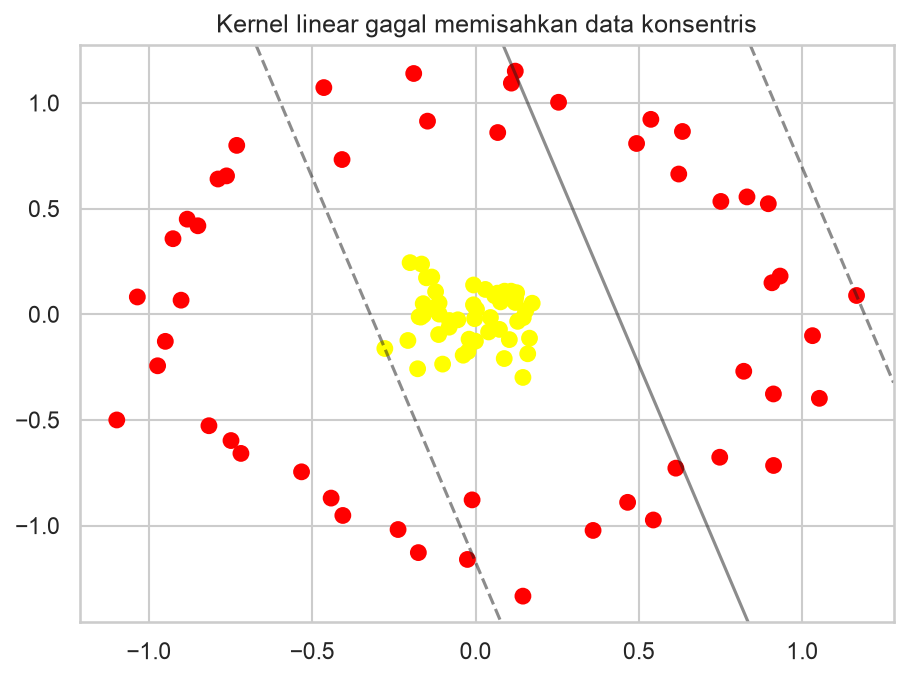

Akurasi kernel linear: 0.68


In [3]:
from sklearn.datasets import make_circles

X, y = make_circles(100, factor=.1, noise=.1, random_state=0)

clf = SVC(kernel='linear').fit(X, y)

plt.figure(figsize=(7, 5))
plt.scatter(X[:, 0], X[:, 1], c=y, s=50, cmap='autumn')
plot_svc_decision_function(clf, plot_support=False)
plt.title('Kernel linear gagal memisahkan data konsentris')
plt.show()

print('Akurasi kernel linear:', clf.score(X, y))

Terlihat bahwa kernel linear tidak menemukan garis pemisah yang berguna — akurasinya hanya **0,68**, dan tetap sekitar **0,70** walaupun `C` diperbesar menjadi `1E6` (lihat tabel di akhir bagian ini). Diperlukan sudut pandang lain terhadap data: **proyeksi radial** yang mengangkat data ke dimensi ketiga,

> **Penyesuaian:** `random_state=0` ditambahkan pada `make_circles`. Pada modul tidak diset, sehingga data dan angka akurasinya berubah setiap kali dijalankan.

$$r = \exp\left(-\sum_i x_i^2\right)$$

In [4]:
r = np.exp(-(X ** 2).sum(1))

print('Nilai r untuk 5 titik pertama:', np.round(r[:5], 4))
print(f'Rentang r: {r.min():.4f} sampai {r.max():.4f}')

Nilai r untuk 5 titik pertama: [0.3993 0.9824 0.4059 0.9977 0.9722]
Rentang r: 0.1653 sampai 0.9996


Karena proyeksi radial tidak cukup digambarkan pada bidang 2D, visualisasinya diubah menjadi 3D. Pada ruang ini kedua kelas dapat dipisahkan oleh sebuah **bidang datar**.

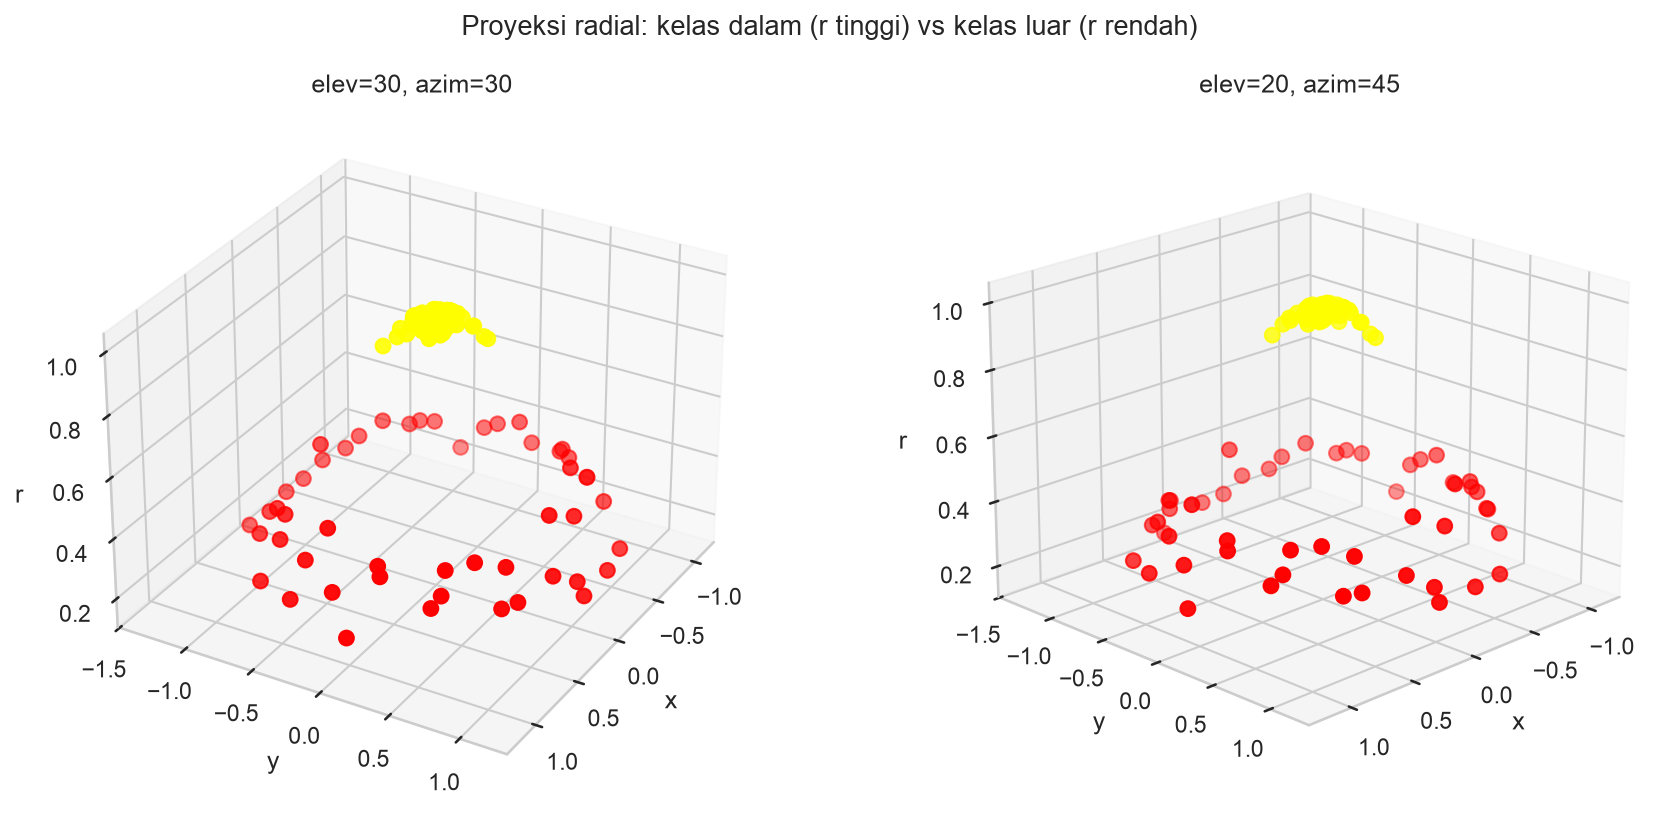

In [5]:
from mpl_toolkits import mplot3d  # noqa: F401 - mengaktifkan proyeksi 3D

fig = plt.figure(figsize=(14, 6))
for i, (elev, azim) in enumerate([(30, 30), (20, 45)], start=1):
    ax = fig.add_subplot(1, 2, i, projection='3d')
    ax.scatter3D(X[:, 0], X[:, 1], r, c=y, s=50, cmap='autumn')
    ax.view_init(elev=elev, azim=azim)
    ax.set_xlabel('x')
    ax.set_ylabel('y')
    ax.set_zlabel('r')
    ax.set_title(f'elev={elev}, azim={azim}')

plt.suptitle('Proyeksi radial: kelas dalam (r tinggi) vs kelas luar (r rendah)', size=13)
plt.show()

> **Penyesuaian:** modul memakai `interact(plot_3D, elev=[-90, 45, 30, 20, 10], azip=(-180, 180), ...)` agar sudut pandang bisa diputar. Karena `ipywidgets` tidak tersedia di lingkungan ini, ditampilkan dua sudut pandang statis. Perhatikan juga salah ketik pada modul: `azip` seharusnya `azim`.

### Langkah 2 - Fitting Model
Memetakan data ke dimensi N untuk N titik tentu menambah beban komputasi. Karena itu, Scikit-Learn menyediakan **kernel RBF** (*Radial Basis Function*) yang menghitung pemetaan tersebut secara implisit lewat inner product.

In [6]:
clf = SVC(kernel='rbf', C=1E6)
clf.fit(X, y)

print('Akurasi kernel RBF:', clf.score(X, y))
print('Jumlah support vector:', int(clf.n_support_.sum()))

Akurasi kernel RBF: 1.0
Jumlah support vector: 10


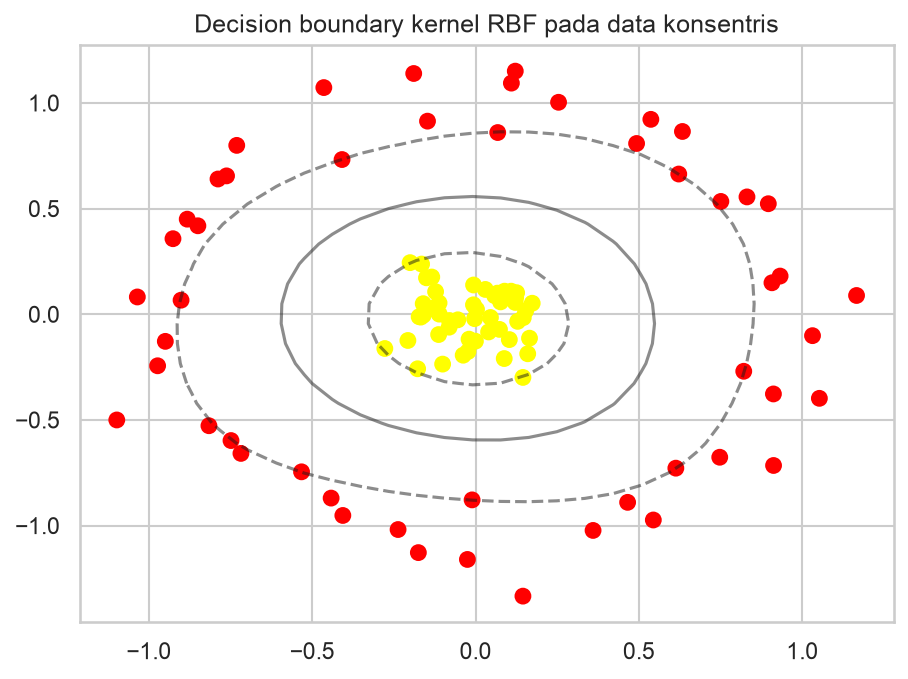

In [7]:
plt.figure(figsize=(7, 5))
plt.scatter(X[:, 0], X[:, 1], c=y, s=50, cmap='autumn')
plot_svc_decision_function(clf)
plt.scatter(clf.support_vectors_[:, 0], clf.support_vectors_[:, 1],
            s=300, lw=1, facecolors='none')
plt.title('Decision boundary kernel RBF pada data konsentris')
plt.show()

Batas keputusan yang dihasilkan melingkar mengikuti pola data, bukan garis lurus. Inilah bukti bahwa kernel trick membuat SVM linier "seolah-olah" bekerja di ruang berdimensi lebih tinggi.

In [8]:
# Perbandingan singkat kernel pada data non-linier (C besar agar mirip hard margin)
hasil = []
for kernel in ['linear', 'poly', 'rbf']:
    m = SVC(kernel=kernel, C=1E6).fit(X, y)
    hasil.append({'Kernel': kernel, 'Akurasi': m.score(X, y),
                  'Jumlah SV': int(m.n_support_.sum())})

import pandas as pd
pd.DataFrame(hasil).round(4)

,Kernel,Akurasi,Jumlah SV
0,linear,0.70,99
1,poly,0.59,99
2,rbf,1.00,10


### Kesimpulan

* Data konsentris tidak dapat dipisahkan kernel linear — akurasinya hanya **0,70** bahkan setelah `C` dinaikkan ke `1E6`, dan `poly` derajat 3 justru lebih buruk (**0,59**).
* Proyeksi radial `r = exp(-(X**2).sum(1))` memperlihatkan bahwa pada ruang 3D kedua kelas justru terpisah oleh bidang datar; ini intuisi di balik **kernel trick**.
* **Kernel RBF** (`C=1E6`) memisahkan data hampir sempurna (akurasi **1,0**) dengan decision boundary melingkar, tanpa perlu menghitung transformasi eksplisit.
* Pemilihan kernel adalah keputusan desain: kenali pola data dulu (linier vs melengkung/konsentris), baru pilih kernel dan setel `C` serta `gamma`.